# V8: bounded score-improvement experiments

Stable serial judge routing, completion of the fixed context cohort, a controlled
structural residual, external-data/teacher audits and a conditional size pilot.
Every quality result uses original votes and historically inspected development
groups. Lower log loss is better; a pilot is not an official leaderboard result.


In [1]:
import json,sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
REPO=Path.cwd().resolve()
if not (REPO/'GOAL.md').exists():REPO=REPO.parent
sys.path.insert(0,str(REPO/'src'))
from arena.data import ROOT
PUB=REPO/'results/span_008';RUN=ROOT/'runs/span_008';FIG=RUN/'figures';FIG.mkdir(parents=True,exist_ok=True)
def read(p):return json.loads(Path(p).read_text())
def save(fig,name):
    for ext in ['png','svg']:fig.savefig(FIG/(name+'.'+ext),dpi=160,bbox_inches='tight')
    plt.show()
cfg=read(REPO/'configs/span_008.json');registry=read(REPO/'backlog/hypotheses.json');v=next(x for x in registry['versions'] if x['number']==8);items={x['id']:x for x in registry['items']}
display(pd.DataFrame([{'task':k,'status':items[k]['status'],'title':items[k]['title']} for k in v['focus_ids']]))
print('Original deadline:',cfg['deadline'],'; charged ceiling:',cfg['gpu_session_seconds_cap'],'seconds')


,task,status,title
0,H52,done,Test a stable serial judge on a fixed10%classi...
1,H51,done,Complete the frozen context cohort from verifi...
2,H36,done,Structural residual correction
3,H17,deferred,Additional public preference data
4,H02,deferred,Larger supervised classifier
5,H15,deferred,Preference-teacher distillation
6,E13,done,Checkpoint full-partition inference with bound...
7,H50,done,Qualify and officially evaluate one frozen v7 ...


Original deadline: 2026-11-07T00:30:17+00:00 ; charged ceiling: 10800 seconds


## Matched loss reductions and gates

Each point compares a candidate with its own matched control. The judge uses the
complete nested fitting chain, context the original frozen temperature, and the
structural residual nested folds with flexible controls. Absolute losses across
different cohorts/recipes are not a common model ranking. Missing comparisons
are displayed as incomplete, never imputed as zero gain.


H52 metrics: {'calibration': 0.94601, 'cascade': 0.946221} runtime: {'classifier_seconds_per_row': 0.6527916988, 'routed_judge_seconds_per_row': 1.0952645863281258, 'measured_setup_and_switch_seconds': 650.8645961248671, 'projected_seconds': 24120.409319109243, 'limit_seconds': 25200, 'passed': True, 'native_load_seconds': [92.10402264999993, 8.011578950000057], 'both_models_serial': True}
H51 metrics: {'short': 0.953962, 'long': 0.951337} runtime: {'conservative_projected_seconds': 25868.069569795978, 'prospective_projected_seconds': 24282.911802511717, 'unchanged_seconds_per_row': 0.586703202734375, 'long_old_seconds_per_row': 1.4678758731752235, 'long_new_seconds_per_row': 1.5742963995976562, 'adopted_long_seconds_per_row': 1.5742963995976562, 'cold_seconds': 141.81904738701314, 'changed_fraction': 0.20048729550991995, 'passed': True}
Frozen confirmation losses: {'frozen_classifier': 0.947161, 'context': 0.945541}


,task,gain,interval_95,groups,rows,replicates,eligible
0,H52,-0.000211,"[-0.00304, 0.002676]",1929,2048,2000,False
1,H51,0.002625,"[0.000675, 0.00459]",5211,5746,2000,True
2,H50 confirmation,0.001620,"[-0.000427, 0.003486]",5174,5746,2000,False
3,H36 vs calibration,0.001072,"[0.000085, 0.001972]",5211,5746,2000,False
4,H36 vs probability_only,0.000982,"[-0.000063, 0.001963]",5211,5746,2000,False
5,H36 vs style,0.002222,"[0.000945, 0.003432]",5211,5746,2000,False


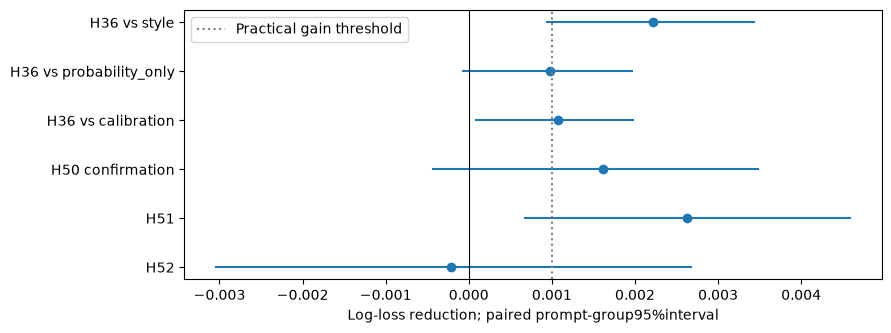

In [2]:
rows=[]
for task in ['H52','H51']:
    r=read(PUB/(task+'_results.json'))
    if r.get('complete'):
        rows.append({'task':task,**r['contrast'],'eligible':r['eligible']})
        print(task,'metrics:',{k:round(m['log_loss'],6) for k,m in r['metrics'].items()},'runtime:',r['runtime'])
    else:print(task,'No full quality comparison:',r.get('reason'),'worker summary:',r.get('worker_summary',{}))
confirmation=read(PUB/'H50_results.json')
if confirmation.get('confirmation_complete'):
    rows.append({'task':'H50 confirmation',**confirmation['contrast'],'eligible':confirmation['eligible_for_official']})
    print('Frozen confirmation losses:',{k:round(v['log_loss'],6) for k,v in confirmation['metrics'].items()})
r=read(PUB/'H36_results.json')
for name,g in r['contrasts'].items():rows.append({'task':'H36 vs '+name,**g,'eligible':r['eligible']})
display(pd.DataFrame(rows))
fig,ax=plt.subplots(figsize=(9,3.5))
for i,r in enumerate(rows):
    ax.plot(r['interval_95'],[i,i],color='C0');ax.scatter(r['gain'],i,color='C0')
ax.axvline(0,color='black',linewidth=.8);ax.axvline(.001,color='grey',linestyle=':',label='Practical gain threshold')
ax.set_yticks(range(len(rows)),[r['task'] for r in rows]);ax.set_xlabel('Log-loss reduction; paired prompt-group95%interval');ax.legend();save(fig,'v8_matched_gains')


## Actual compute and model-size pilot

Promotion and size pilot share a single mutually exclusive5400-second reserve.
Compute bars include setup and failed work. The size experiment, if admitted,
starts fresh classifier heads and runs only32accepted updates. It measures a
short learning/throughput regime, not a trained competition model. A size effect
requires equal packed inputs and reconciled accepted row/token exposure.


,role,charged_seconds,cap_seconds,stage
0,serial_cascade,3110.246,3600,complete
1,context_completion,857.458,1800,complete
2,promotion,4381.364,5400,complete
3,size_pilot,0.000,5400,not executed


Total charged: 8349.068 seconds


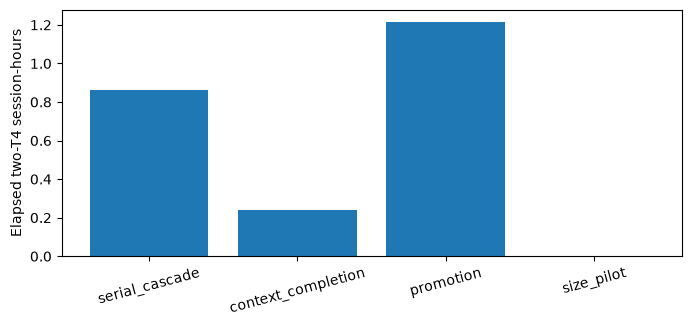

Size pilot was not admitted; see the frozen candidate decision.


In [3]:
charges=[]
for role,cap in cfg['job_seconds_caps'].items():
    p=PUB/'jobs'/role/'controller_state.json';r=read(p) if p.exists() else {}
    charges.append({'role':role,'charged_seconds':r.get('charged_seconds',0),'cap_seconds':cap,'stage':r.get('stage','not executed')})
display(pd.DataFrame(charges));print('Total charged:',sum(r['charged_seconds'] for r in charges),'seconds')
fig,ax=plt.subplots(figsize=(8,3.2));ax.bar([r['role'] for r in charges],[r['charged_seconds']/3600 for r in charges]);ax.set_ylabel('Elapsed two-T4 session-hours');ax.tick_params(axis='x',rotation=15);save(fig,'v8_compute')
p=PUB/'H02_results.json'
if p.exists() and read(p).get('executed',True):
    size=read(p);print('Matched exposure:',size.get('quality_comparison_valid'),'paired result:',size.get('raw_paired_gain'))
    display(pd.DataFrame([{'size':k,'complete':r['complete'],'raw_loss':r.get('raw_metrics',{}).get('log_loss'),'accepted_updates':r.get('accepted_updates'),
        'accepted_rows':r.get('global_accepted_rows'),'accepted_tokens':r.get('global_accepted_tokens'),'train_seconds':r.get('training_seconds'),'inference_seconds_per_row':r.get('prediction_seconds_per_row')} for k,r in size['arms'].items()]))
    fig,axes=plt.subplots(1,2,figsize=(10,3.2))
    for k,r in size['arms'].items():
        curves=r.get('loss_curve',[]);loss=[v for v in curves if v.get('loss') is not None]
        if loss:axes[0].plot([v['step'] for v in loss],[v['loss'] for v in loss],label=k)
        c=r.get('training_curve',[])
        if c:axes[1].plot([v['elapsed_seconds'] for v in c],[v['accepted_updates'] for v in c],label=k)
    axes[0].set(xlabel='Nominal optimizer cycle',ylabel='Logged training CE');axes[1].set(xlabel='Elapsed training seconds',ylabel='Accepted updates')
    for ax in axes:
        if ax.lines:ax.legend()
    save(fig,'v8_size_learning')
else:print('Size pilot was not admitted; see the frozen candidate decision.')


## External data and teacher validity

Exact and detected near overlap are purged; approximate retrieval does not prove
absence of semantic overlap. Equal synthetic scores are not human tie labels.
The public final teacher merge cannot establish independent advantage if its
training included these competition evaluation votes. No external mixed-data
training or distillation is implied by a completed preparation audit.


Downloaded: 60829 provisionally usable: 54926
Target semantics: {'annotation': 'Synthetic GPT-4 ranked responses; chosen/rejected is not a human three-class vote', 'equal_score_rows': 3808, 'reversed_score_rows': 0, 'identical_answer_rows': 359, 'empty_answer_rows': 151, 'gap_quantiles': [0.0, 1.0, 1.5, 3.0, 6.0, 9.0], 'human_tie_labels_available': False, 'equal_scores_are_not_valid_human_tie_labels': True}


,exact_prompt_rows,exact_any_answer_rows
train,13,1764
dev,3,814
confirmation,2,1116


Near matching: {'retrieval': 'Eight minimum BLAKE2b hashes of unique five-word shingles; any hash candidate, exact Jaccard verification >=0.8', 'scope': 'All prompts and all answers against all competition partitions, using text only', 'candidate_pairs_verified': 3242166, 'recall_guaranteed': False, 'short_texts_under_five_words': 'Exact matching only', 'semantic_overlap_tested': False}
Teacher decision: Defer actual distillation until a stronger teacher is measured without supervised access to evaluation groups. Public solution is architectural evidence, not a clean benchmark or adopted checkpoint.


,cohort,median_chars,p95_chars,code_fraction,refusal_proxy
0,competition_prompt,92.0,1427.00,0.007464,0.015032
1,competition_answer,1041.0,3588.35,0.097404,0.099266
2,external_prompt,356.0,2452.60,0.005540,0.023706
3,external_answer,739.0,3327.15,0.090458,0.083291


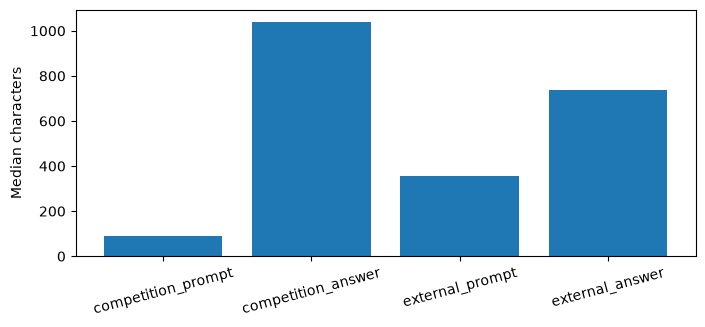

In [4]:
data=read(PUB/'H17_audit.json');teacher=read(PUB/'H15_audit.json')
print('Downloaded:',data['external_rows'],'provisionally usable:',data['provisionally_usable_rows'])
print('Target semantics:',data['target_semantics']);display(pd.DataFrame(data['exact_overlap']).T)
print('Near matching:',data['near_method']);print('Teacher decision:',teacher['decision'])
profiles=data['profiles'];display(pd.DataFrame([{'cohort':k,'median_chars':v['characters_quantiles'][2],'p95_chars':v['characters_quantiles'][4],'code_fraction':v['code_fraction'],'refusal_proxy':v['refusal_proxy_fraction']} for k,v in profiles.items()]))
fig,ax=plt.subplots(figsize=(8,3.2));ax.bar(list(profiles),[v['characters_quantiles'][2] for v in profiles.values()]);ax.set_ylabel('Median characters');ax.tick_params(axis='x',rotation=15);save(fig,'v8_text_lengths')


## Frozen selection, official result and version boundary

The fixed priority is judge, context, structure, conditional on all declared
quality/runtime gates. Confirmation is evaluated only after freezing one
candidate. The historical cohorts remain described as inspected. No successor
backlog task is executed when this span closes.


In [5]:
selection=read(PUB/'candidate_selection.json');display(selection)
for name in ['H50_results.json','terminal_audit.json','validation.json']:
    p=PUB/name
    if p.exists():display(read(p))
print('V8 state:',v['state'],'active version:',registry['active_version'])
print('See docs/SPAN_008_RESULTS.md and the completion record for decisions, limitations and artifact proofs.')


{'frozen_at': '2026-11-06T15:39:00.713371+00:00',
 'eligible': True,
 'candidate_kind': 'context_completion',
 'priority': ['serial_cascade', 'context_completion', 'structure'],
 'confirmation_targets_used': False,
 'input_sha256': {'serial_cascade': 'db183965a7896dc4b823546a0c2d76f24563dc1c906a9d72dbd8e60d99c0baec',
  'context_completion': '80ed374030d7313b241da49e243ff62eea4883d82e763dc2c5d893d045f4e72b',
  'structure': '75426c800f08e70128fe9cf4259c16c44283eec243d7b5555158620c6bc56956'},
 'source_sha256': '4fdf6a4e4a30cde5b28ee654cfdbc65e54605d2bceddf888fa6f7fe7cc6dd27c'}

{'task': 'H50',
 'executed': True,
 'confirmation_complete': True,
 'confirmation_historically_inspected': True,
 'fit_operations': 0,
 'parameters_frozen_before_vote_access': True,
 'metrics': {'frozen_classifier': {'rows': 5746,
   'log_loss': 0.9471606394051313,
   'accuracy': 0.5421162547859381,
   'macro_f1': 0.5344501304776728,
   'brier': 0.5632473389238745,
   'class_counts': [2006, 1964, 1776],
   'class_loss': [0.9048415222662315, 0.8944279996444903, 1.0532749713142144],
   'class_recall': [0.6036889332003988, 0.609979633401222, 0.3975225225225225],
   'tie_precision': 0.5123367198838897,
   'mean_predictive_entropy': 0.9524374687327611,
   'mean_class_probability': [0.34298015381840485,
    0.34561281916999337,
    0.31140702701160305],
   'predicted_class_fraction': [0.3788722589627567,
    0.3813087365123564,
    0.2398190045248869],
   'tie_auc': 0.6911847300701205,
   'confusion_matrix': [[1211, 445, 350], [444, 1198, 322], [522, 548, 706]]},
  'context': {'rows': 5746,


{'passed': True,
 'checked_at': '2026-11-06T17:19:27.589442+00:00',
 'jobs': [{'role': 'serial_cascade',
   'kernel_version': 'arseniytrushin/llm-preference-span008-serial-cascade/1',
   'status': 'COMPLETE',
   'charged_seconds': 3110.245999999999,
   'source_verified': True,
   'retrieved_files_verified': 163},
  {'role': 'context_completion',
   'kernel_version': 'arseniytrushin/llm-preference-span008-context-completion/1',
   'status': 'COMPLETE',
   'charged_seconds': 857.4580000000133,
   'source_verified': True,
   'retrieved_files_verified': 36},
  {'role': 'promotion',
   'kernel_version': 'arseniytrushin/llm-preference-span008-context-promotion/1',
   'status': 'COMPLETE',
   'charged_seconds': 4381.363999999987,
   'source_verified': True,
   'retrieved_files_verified': 90}],
 'inventory': {'observed_at': '2026-11-06T17:19:26.487381+00:00',
  'quota': {'used_seconds': 105113.055,
   'reserved_seconds': 0.0,
   'allowed_seconds': 108000.0,
   'refresh_time': '2026-11-07 00:00

{'passed': True,
 'checked_at': '2026-11-06T17:21:40.090636+00:00',
 'tests': 110,
 'seconds': 13.305,
 'command': 'OMP_NUM_THREADS=2 OPENBLAS_NUM_THREADS=2 MKL_NUM_THREADS=2 .venv/bin/python -m unittest discover -s tests -p test_*.py -v',
 'test_log_sha256': '0dea6b13bae14f0c5fcf2cbec5457f428ac1f1bb0b681384975176a4b7c99d22',
 'tests_source_sha256': {'tests/test_backlog.py': '4010623ea99bb805a4122101dfec362b1c440655d0d9699bcb1996dc79b46ba4',
  'tests/test_context_route.py': '597facd999cfb60ed5a2287c7910a50006092ce45664a285fd7a2fb2a866df03',
  'tests/test_eda.py': 'e4a07f0166618b4303ba710844e666d4247ef73ef1c365f86be11e927931a772',
  'tests/test_error_poster.py': 'ed60ee7ca24bb2bbfa329544080d89d0f84a6937a807df3e96e16049dd6ab301',
  'tests/test_experiment.py': '23eb328b9e745a921e7531b58b6e6d98ab67fb58512c4655cc49f70d3a4c9803',
  'tests/test_invariants.py': 'cc1ab595b99e94622b8bb2f59cbe5bba2fc95af567acbb2defa6a939e7e6aa32',
  'tests/test_joint.py': '4661edf7a45c8e246f84340cd1050890b179c3ef

V8 state: closed active version: 9
See docs/SPAN_008_RESULTS.md and the completion record for decisions, limitations and artifact proofs.
